In [41]:
# Titanic Survival Prediction

# Objective

#Build a machine learning model to predict whether a Titanic passenger survived based on passenger characteristics.

## Features

#- Passenger class
#- Sex
#- Age
#- Fare

## Models

#- Logistic Regression
#- Decision Tree
#- Random Forest

## Final Model

#Random Forest with hyperparameter tuning using GridSearchCV.

In [1]:
#Load Titanic data
import pandas as pd
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.shape

(891, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
#Understand the Target
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [5]:
#Choose features
features = ["Pclass", "Sex", "Age", "Fare"]
x = df[features]
y = df["Survived"]

In [6]:
#Check missing data
x.isnull().sum()

Pclass      0
Sex         0
Age       177
Fare        0
dtype: int64

In [7]:
x = x.copy()
x["Age"] = x["Age"].fillna(x["Age"].median())

In [8]:
x.isnull().sum()

Pclass    0
Sex       0
Age       0
Fare      0
dtype: int64

In [9]:
#Convert text into numbers
x = pd.get_dummies(x, columns=["Sex"], drop_first=True)
x.head()

,Pclass,Age,Fare,Sex_male
0,3,22.0,7.2500,True
1,1,38.0,71.2833,False
2,3,26.0,7.9250,False
3,1,35.0,53.1000,False
4,3,35.0,8.0500,True


In [10]:
#Split the data
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size = 0.2, random_state=42, stratify=y)


In [11]:
#Train the model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [12]:
#Make Predictions
y_pred = model.predict(x_test)
print(y_pred[:10])

[0 0 0 0 1 0 1 0 0 0]


In [13]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7877094972067039


In [14]:
#Evaluate the titanic model
#Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[94 16]
 [22 47]]


In [15]:
#Precision, Recall, F1
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.85      0.83       110
           1       0.75      0.68      0.71        69

    accuracy                           0.79       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179



In [16]:
#Start fresh with original data
x = df[["Pclass", "Sex", "Age", "Fare"]]
y = df["Survived"]

In [18]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
numeric_features = ["Pclass", "Age", "Fare"]
categorical_features = ["Sex"]


In [21]:
#For numbers
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
#For text
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


In [22]:
#Build the complete ML pipeline
from sklearn.linear_model import LogisticRegression
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(x_train, y_train)
y_pred = model.predict(x_test)

from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7932960893854749


In [23]:
#Compare 3 models

In [24]:
#Import the models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [25]:
#Train and compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}
results = {}

for name,classifier in models.items():
    pipeline = Pipeline([
        ("preprocessing",preprocessor),
        ("classifier",classifier)
    ])
    pipeline.fit(x_train, y_train)
    predictions = pipeline.predict(x_test)
    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy
    print(f"{name}: {accuracy:.2%}")

Logistic Regression: 79.33%
Decision Tree: 81.01%
Random Forest: 83.24%


In [26]:
#Compare the results
import pandas as pd
results_df = pd.DataFrame(
    results.items(),
    columns = ["Model", "Accuracy"]
)
results_df

,Model,Accuracy
0,Logistic Regression,0.793296
1,Decision Tree,0.810056
2,Random Forest,0.832402


In [28]:
#Cross Validation
#Instead of doing just one train/test split, we can test the model multiple items. We'll use 5-fold cross-validation.

from sklearn.model_selection import cross_val_score
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=5,
    scoring = "accuracy"
)
print("Scores:",scores)
print("Average:", scores.mean())


Scores: [0.75977654 0.80898876 0.84831461 0.79213483 0.84831461]
Average: 0.8115058690603225


In [30]:
#hyperparameters
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

for depth in [2,4,6,8,None]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=depth,
            random_state=42
            ))
         ])
    scores = cross_val_score(
        pipeline,
        x,
        y,
        cv=5,
        scoring = "accuracy"
    )
    print(depth, round(scores.mean(), 3))

2 0.787
4 0.819
6 0.826
8 0.838
None 0.812


In [33]:
#GridSearchCV

#Create the pipeline
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

#define the settings to rest
param_grid = {
    "classifier__n_estimators": [50,100,200],
    "classifier__max_depth":[3, 5, 7, None]
}

#Run GridSearchCV
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(x_train,y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best CV score:")
print(grid_search.best_score_)

#Evaluate on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)

from sklearn.metrics import accuracy_score
print("Test accuracy:", accuracy_score(y_test, y_pred))

Best parameters:
{'classifier__max_depth': 7, 'classifier__n_estimators': 50}
Best CV score:
0.827331823106471
Test accuracy: 0.8268156424581006


              precision    recall  f1-score   support

           0       0.82      0.92      0.87       110
           1       0.84      0.68      0.75        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179

[[101   9]
 [ 22  47]]


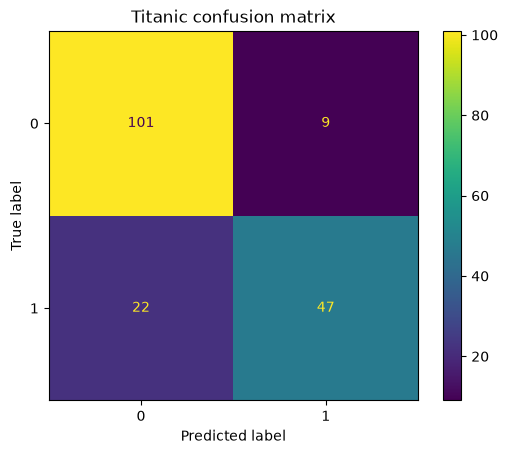

In [34]:
#Final model evaluation

#Classification report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

#confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.title("Titanic confusion matrix")
plt.show()

In [36]:
#Feature importance
rf = best_model.named_steps["classifier"]
feature_names = best_model.named_steps[
    "preprocessing"
    ].get_feature_names_out()

importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending = False
)
feature_importance



,Feature,Importance
4,cat__Sex_male,0.254209
2,num__Fare,0.241508
1,num__Age,0.214119
3,cat__Sex_female,0.166322
0,num__Pclass,0.123842


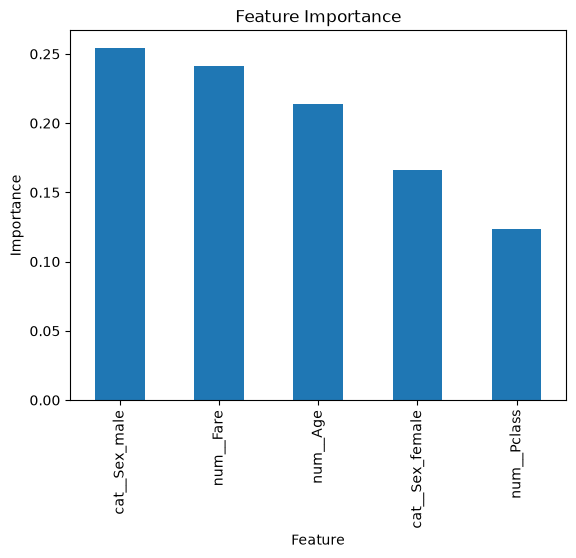

In [37]:
feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False
)
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()

In [39]:
#Make predictions on new passengers
new_passenger = pd.DataFrame({
    "Pclass":[1],
    "Sex":["female"],
    "Age":[30],
    "Fare":[100]
        })

#Make the prediction
prediction = best_model.predict(new_passenger)
print(prediction)

probability = best_model.predict_proba(new_passenger)
print(probability)

#Try another passenger
passenger = pd.DataFrame({
    "Pclass":[3],
    "Sex":["male"],
    "Age":[40],
    "Fare":[10]
})
prediction = best_model.predict(passenger)
print("Prediction:", prediction[0])

[1]
[[3.17460317e-04 9.99682540e-01]]
Prediction: 0
